# PlantDoc Dataset EDA

This notebook explores the `geraldmc/plantdoc-full` dataset for plant disease classification. The analysis checks the dataset structure, metadata quality, class balance, split composition, and visual diversity of the leaf images.

The main questions are:

- How many images and disease classes are available?
- Are classes and splits balanced enough for reliable training and evaluation?
- Are there missing values or duplicate metadata records?
- Do image dimensions and sample images look consistent?


In [1]:
%pip install dataset pandas matplotlib pillow tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 18.4 MB/s eta 0:00:00


## 1. Load the dataset

Install or import the libraries needed for dataset loading, tabular summaries, and visual inspection.


In [1]:
from datasets import load_dataset

ds = load_dataset("geraldmc/plantdoc-full")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/9.16k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  476MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  516MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2578 [00:00<?, ? examples/s]

In [7]:
ds

DatasetDict({
    train: Dataset({
        features: ['image', 'class_label', 'class_idx', 'host', 'disease', 'is_healthy', 'split', 'filename'],
        num_rows: 2578
    })
})

## 2. Inspect the dataset structure

The dataset object shows the available splits and feature types. Confirming this structure early helps prevent accidental leakage between training and evaluation data.


In [2]:
import pandas as pd
from datasets import concatenate_datasets

d = concatenate_datasets(list(ds.values())) # one table; the train/test info is in the "split" column
d.features

{'image': Image(mode=None, decode=True),
 'class_label': Value('string'),
 'class_idx': Value('int64'),
 'host': Value('string'),
 'disease': Value('string'),
 'is_healthy': Value('bool'),
 'split': Value('string'),
 'filename': Value('string')}

## 3. Combine splits and inspect features

The split datasets are concatenated for general exploration. The original split label remains available in the `split` column, allowing us to compare distributions without losing the train/test assignment.


In [3]:
df = d.to_pandas()

In [4]:
metadata = df.drop(columns=["image"])
metadata.head()

,class_label,class_idx,host,disease,is_healthy,split,filename
0,Apple Scab Leaf,0,Apple,scab,False,train,01Apple-scab-2-Venturia-inaequalis.ashx?w=600&...
1,Apple Scab Leaf,0,Apple,scab,False,train,11NovMW_W4-A_4b.jpg
2,Apple Scab Leaf,0,Apple,scab,False,train,12-20_apple_scab1.jpg
3,Apple Scab Leaf,0,Apple,scab,False,train,500_F_125294801_k0A2teQwKxZfTV1pcaerZFf9Th04F0...
4,Apple Scab Leaf,0,Apple,scab,False,train,6A642AA3-1DB1-4413-B0B6-7FBB68A5904A_original....


## 4. Build a metadata table

Images are kept in the Hugging Face dataset, while a metadata-only table makes tabular checks faster and easier to read.


## 5. Basic data-quality checks

These checks identify missing metadata, repeated rows, and the overall number of examples and classes. Any issues found here should be resolved before creating training splits or reporting model metrics.


In [30]:
quality_summary = pd.Series({
    "images": len(metadata),
    "classes": metadata["class_label"].nunique(),
    "splits": metadata["split"].nunique(),
    "duplicate_rows": metadata.duplicated().sum(),
})

print(quality_summary)
print("\nMissing values by column:")
display(metadata.isna().sum().sort_values(ascending=False).to_frame("missing"))


images            2578
classes             28
splits               2
duplicate_rows       0
dtype: int64

Missing values by column:


,missing
class_label,0
class_idx,0
host,0
disease,0
is_healthy,0
split,0
filename,0


In [26]:
from matplotlib import pyplot as plt
metadata.info()
metadata["split"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2578 entries, 0 to 2577
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   class_label  2578 non-null   object
 1   class_idx    2578 non-null   int64 
 2   host         2578 non-null   object
 3   disease      2578 non-null   object
 4   is_healthy   2578 non-null   bool  
 5   split        2578 non-null   object
 6   filename     2578 non-null   object
dtypes: bool(1), int64(1), object(5)
memory usage: 123.5+ KB


,count
split,
train,2342
test,236


## 6. Examine split and class balance

A model can look accurate while performing poorly on rare diseases. Comparing class counts within each split reveals imbalance and helps verify that every class is represented in evaluation data.


split,test,train
class_label,,
Apple Scab Leaf,10,83
Apple leaf,9,82
Apple rust leaf,10,79
Bell_pepper leaf,8,53
Bell_pepper leaf spot,9,62
Blueberry leaf,11,106
Cherry leaf,10,47
Corn Gray leaf spot,4,64
Corn leaf blight,12,180


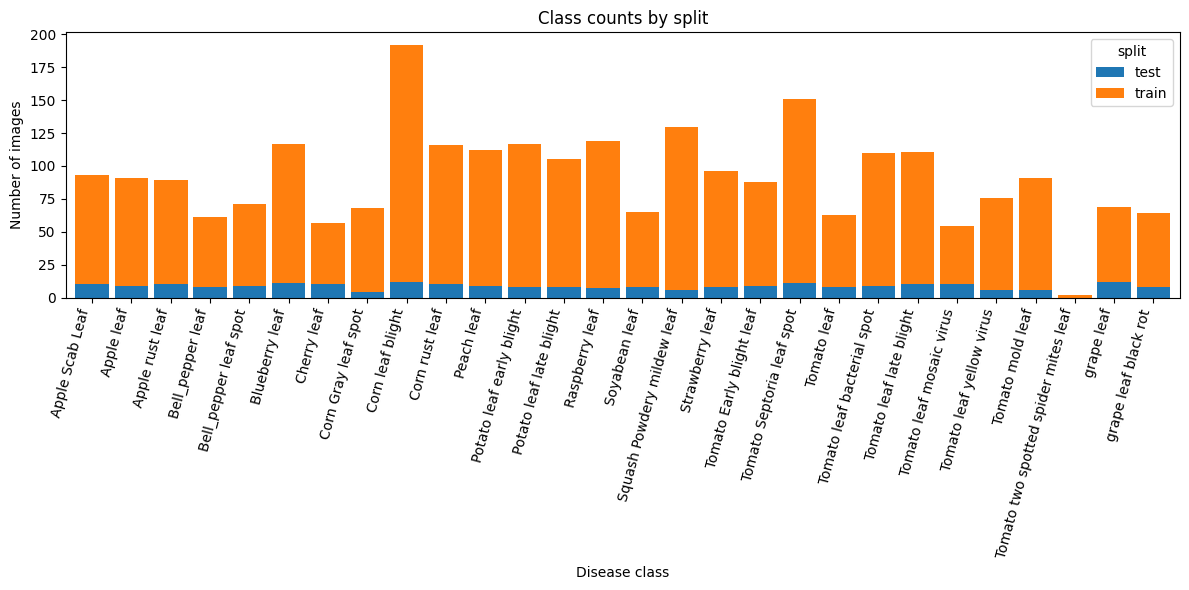

In [32]:
split_class_counts = pd.crosstab(metadata["class_label"], metadata["split"])
display(split_class_counts)

ax = split_class_counts.plot(kind="bar", stacked=True, figsize=(12, 6), width=0.85)
ax.set_title("Class counts by split")
ax.set_xlabel("Disease class")
ax.set_ylabel("Number of images")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()


## 7. Visualize class frequency

The class-frequency plot makes long-tail behavior easy to spot. Large differences in sample counts may require class-weighted loss, balanced sampling, or targeted augmentation during training.


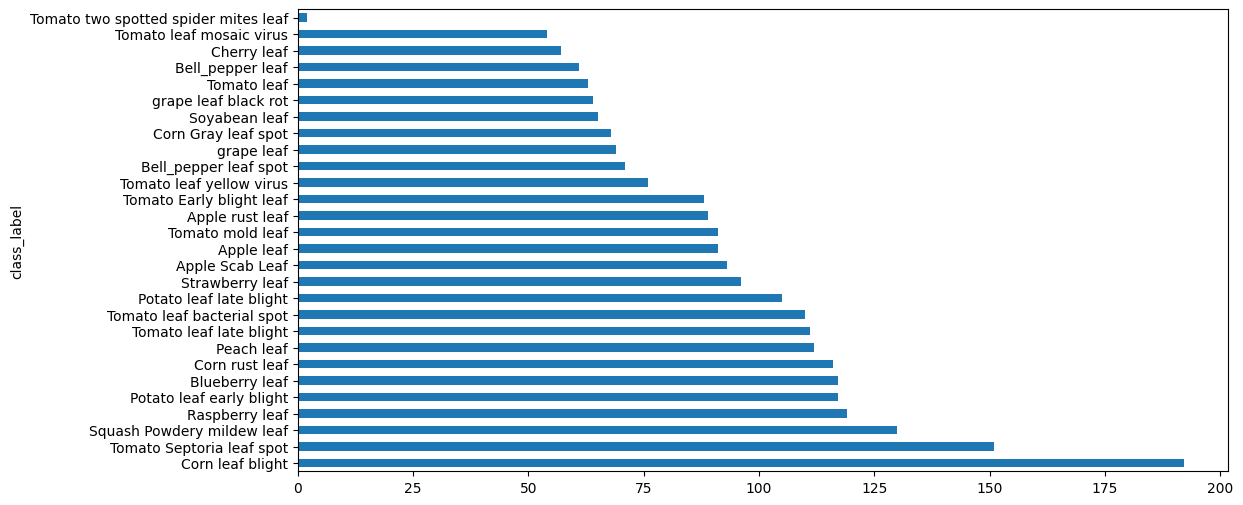

In [29]:
from matplotlib import pyplot as plt
metadata["class_label"].value_counts().plot(kind="barh", figsize=(12, 6))
plt.show()


In [38]:
metadata["is_healthy"].value_counts()

,count
is_healthy,
False,1728
True,850


In [59]:
metadata.isna().sum()

,0
class_label,0
class_idx,0
host,0
disease,0
is_healthy,0
split,0
filename,0


In [60]:
metadata.duplicated().sum()

np.int64(0)

In [61]:
metadata["filename"].duplicated().sum()

np.int64(16)

In [5]:
sel = metadata[metadata.host.str.contains("tomato|apple|corn", case=False)]
print(sel.groupby(["host", "class_label"]).size())
print(len(sel), "images,", sel.class_label.nunique(), "classes")

host    class_label                         
Apple   Apple Scab Leaf                          93
        Apple leaf                               91
        Apple rust leaf                          89
Corn    Corn Gray leaf spot                      68
        Corn leaf blight                        192
        Corn rust leaf                          116
Tomato  Tomato Early blight leaf                 88
        Tomato Septoria leaf spot               151
        Tomato leaf                              63
        Tomato leaf bacterial spot              110
        Tomato leaf late blight                 111
        Tomato leaf mosaic virus                 54
        Tomato leaf yellow virus                 76
        Tomato mold leaf                         91
        Tomato two spotted spider mites leaf      2
dtype: int64
1395 images, 15 classes


## 8. Inspect image dimensions

Image dimensions can vary across datasets and affect preprocessing choices. Measuring the raw dimensions helps determine whether resizing or aspect-ratio handling needs special attention.


In [35]:
from collections import Counter
from io import BytesIO
from pathlib import Path
from PIL import Image


def get_image_size(image_record):
    if hasattr(image_record, "size"):
        return image_record.size
    if image_record.get("bytes") is not None:
        with Image.open(BytesIO(image_record["bytes"])) as image:
            return image.size
    if image_record.get("path") is not None:
        with Image.open(Path(image_record["path"])) as image:
            return image.size
    raise ValueError("Image record contains neither bytes nor path")


image_sizes = Counter(get_image_size(image) for image in df["image"])
size_summary = pd.DataFrame(
    [(width, height, count) for (width, height), count in image_sizes.items()],
    columns=["width", "height", "images"],
).sort_values("images", ascending=False)

display(size_summary.head(15))
print(f"Unique image sizes: {len(size_summary)}")


,width,height,images
56,1600,1200,64
8,800,600,58
47,1024,768,56
163,640,480,30
153,3264,2448,25
365,1200,1600,25
254,900,675,22
204,1200,900,19
48,400,300,19
157,500,375,19


Unique image sizes: 1506


## 9. Review sample images by class

Visual inspection can reveal label noise, confusing disease categories, background variation, and differences in lighting or image quality. The helper below displays a small, reproducible sample for each selected class.


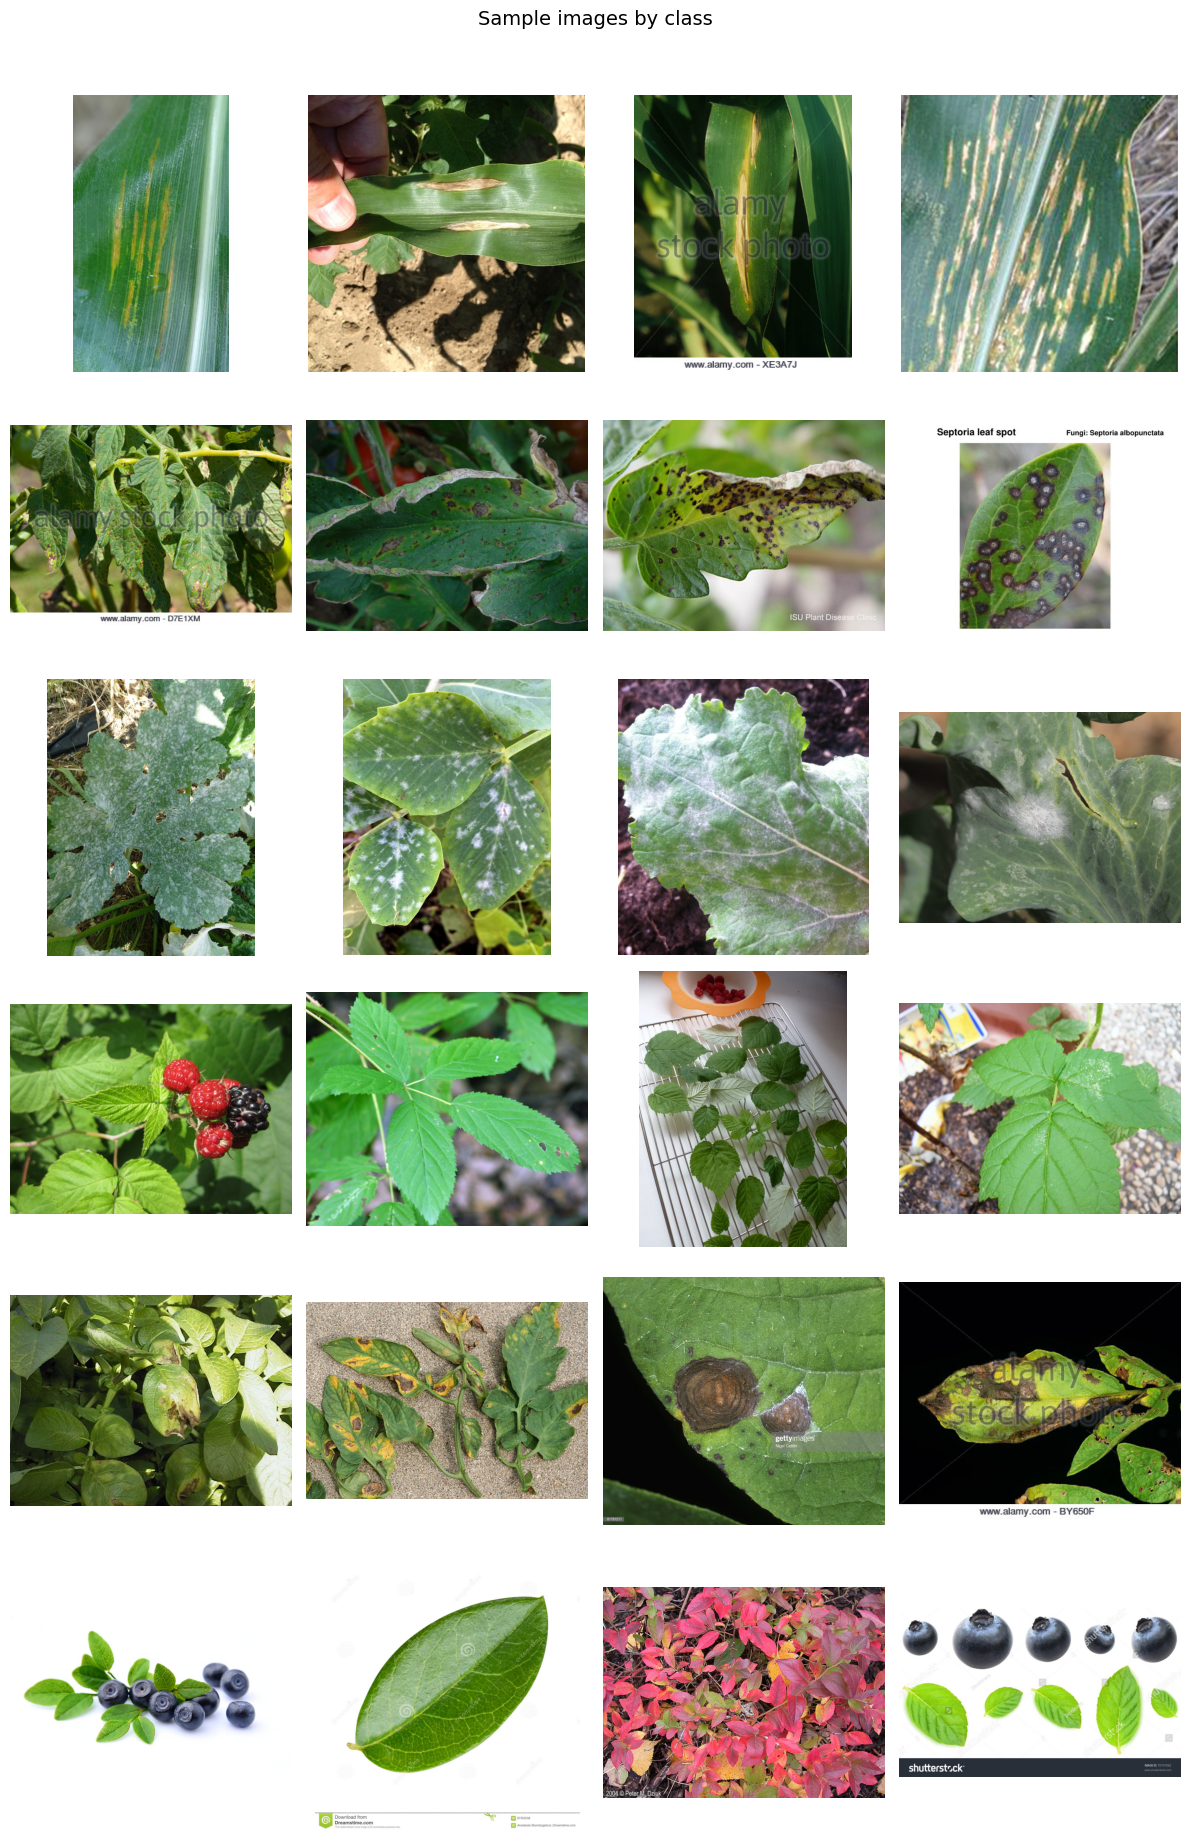

In [36]:
def load_image(image_record):
    if hasattr(image_record, "convert"):
        return image_record.convert("RGB")
    if image_record.get("bytes") is not None:
        return Image.open(BytesIO(image_record["bytes"])).convert("RGB")
    if image_record.get("path") is not None:
        return Image.open(Path(image_record["path"])).convert("RGB")
    raise ValueError("Image record contains neither bytes nor path")


def show_samples_by_class(labels=None, samples_per_class=4, seed=0):
    if labels is None:
        labels = metadata["class_label"].value_counts().head(6).index.tolist()

    figure, axes = plt.subplots(
        len(labels), samples_per_class,
        figsize=(3 * samples_per_class, 3 * len(labels)),
        squeeze=False,
    )

    for row, label in enumerate(labels):
        class_rows = metadata[metadata["class_label"] == label]
        sample_rows = class_rows.sample(
            n=min(samples_per_class, len(class_rows)),
            random_state=seed,
        )

        for column in range(samples_per_class):
            axis = axes[row, column]
            axis.axis("off")
            if column < len(sample_rows):
                image = load_image(df.loc[sample_rows.index[column], "image"])
                axis.imshow(image)
            if column == 0:
                axis.set_ylabel(label, rotation=0, ha="right", va="center", labelpad=45)

    figure.suptitle("Sample images by class", y=1.02, fontsize=14)
    figure.tight_layout()
    plt.show()


show_samples_by_class()


## 10. EDA takeaways

### Dataset size and number of disease classes:
  - size : 2578
  - healthy plant images : 850
  - number of disease classes : 18
### Dominant and rare classes:
 - Dominant : corn leaf blight, tomato septoria leaf spot
 - Rare: tomato two spotted spider mites leaf
### Missing or duplicated metadata:
 - Duplicate file names : 16
### Image resizing and augmentation considerations: 
 - **all images should be resized to 224 x 224**

These findings should be reviewed before building the training pipeline and selecting evaluation metrics.
